# Utilisation d’un algorithme de boosting sur de la reconnaissance de chiffres manuscrit


In [36]:
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
import numpy as np

directory = "../data"
mnist = fetch_openml('mnist_784', version=1, data_home=directory, as_frame=False, parser='liac-arff')

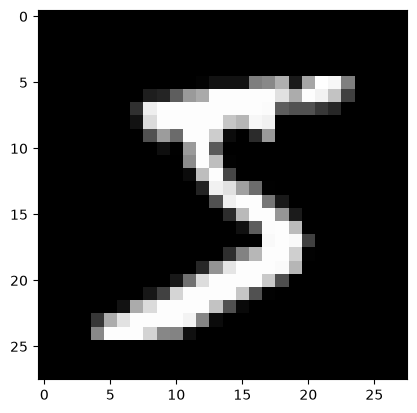

In [37]:
Xtrain = mnist.data[0:60000]
Ytrain = mnist.target[0:60000]

Xtest = mnist.data[60000:70000]
Ytest = mnist.target[60000:70000]
#Afficher une image du jeu de train
plt.imshow(Xtrain[0].reshape(28,28), cmap='gray')

random_seed = 1234


## Vérifications

<BarContainer object of 10 artists>

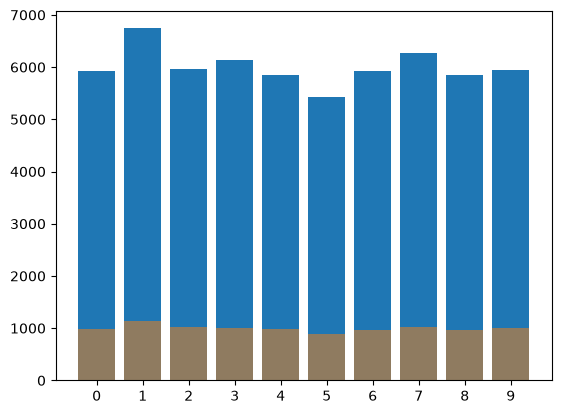

In [38]:
# Equillibrage des classes
plt.bar(np.unique(Ytrain), np.bincount(Ytrain.astype(int)))
plt.bar(np.unique(Ytest), np.bincount(Ytest.astype(int)), alpha=0.5)

## Definition d'adaboost

In [46]:
from curses.ascii import RS

from matplotlib.pyplot import subplot
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix
#import precision recall
from sklearn.metrics import precision_score, recall_score

def apply_adaboost(model,n,lr,Xtrain=Xtrain, Ytrain=Ytrain, standardize=False):
    """
    model : classifieur à deux classes
    n : nombre d'itérations
    lr : learning rate
    """
    if standardize:
        moyenne = np.mean(Xtrain, axis=0)
        sigma = np.std(Xtrain, axis=0)
        Xtrain = (Xtrain - moyenne) / sigma
        print("contient des nan : ", np.isnan(Xtrain).any())
    classes = np.unique(Ytrain)
    classifiers = []
    for c in classes:
        # on construit un classifieur pour chaque classes
        clf = AdaBoostClassifier(estimator = model, n_estimators=n, learning_rate=lr, random_state=random_seed)
        mask = Ytrain == c
        ytrain_binary = mask.astype(int)
        clf.fit(Xtrain, ytrain_binary) 
        classifiers.append(clf)

    return classifiers

def metriques(classifiers, standardize=False):
    metrics = []
    fig , axs = plt.subplots(1, len(classifiers), figsize=(15, 6))
    for i, (c, clf) in enumerate(zip(np.unique(Ytrain), classifiers)):
        if standardize:
            moyenne = np.mean(Xtrain, axis=0)
            sigma = np.std(Xtrain, axis=0)
            Xtest = (Xtest - moyenne) / sigma
        y_true_test = (Ytest == c).astype(int)
        Yhat = clf.predict(Xtest)
        cm = confusion_matrix(y_true_test, Yhat, labels=['-', '+'])
        recall = recall_score(y_true_test, Yhat, average='macro')
        precision = precision_score(y_true_test, Yhat, average='macro')
        metrics.append((cm, recall, precision))
        axs[i].set_title(f'Classe {c}\nRecall: {recall:.2f}, Precision: {precision:.2f}')
        axs[i].imshow(cm, cmap='Blues')
        axs[i].set_xlabel('Prédictions')
    plt.show()
    return metrics

On va utiliser différents apprentisseur-faibles:
 - MLP (`liste des couches et de leurs unités`)
 - décision stumps (aucun parametres)
 - arbre de décision (`profondeur de l'arbre`)

In [44]:
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

mlp_weaklearner = MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=random_seed)
decision_stump = DecisionTreeClassifier(max_depth=1, random_state=random_seed)
decision_tree_weaklearner = DecisionTreeClassifier(max_depth=10, random_state=random_seed)


In [ ]:
mlp_classifiers = apply_adaboost(mlp_weaklearner, n=50, lr=1, standardize=True)
mlp_metrics = metriques(mlp_classifiers, standardize=True)